# FSL TCN — Results and Evaluation

**Project:** Hi-Five — Dynamic Isolated Sign Language Recognition  
**Dataset:** FSL-105 (Filipino Sign Language)  
**Model:** Temporal Convolutional Network (TCN)  
**Features:** 302-dim MediaPipe landmarks per frame, 64-frame sequences  
**Evaluation:** Official FSL-105 test set


In [1]:
import csv
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from collections import defaultdict

import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

PROJECT_ROOT = Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from training.tcn import SignTCN

# Paths
FEATURES_DIR  = PROJECT_ROOT / 'data/FSL-105/features'
TEST_DIR      = FEATURES_DIR / 'test'
TEST_MANIFEST = FEATURES_DIR / 'test_manifest.csv'
TRAIN_MANIFEST = FEATURES_DIR / 'train_manifest.csv'
LABEL_MAP     = PROJECT_ROOT / 'models/fsl_label_map.csv'
MODEL_PATH    = PROJECT_ROOT / 'models/fsl_tcn.pth'
TRAINING_LOG  = PROJECT_ROOT / 'models/fsl_training_log.csv'

# Output folder
OUTPUT_DIR = PROJECT_ROOT / 'results/fsl'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BATCH_SIZE = 32
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
print(f'Model: {MODEL_PATH}')
print(f'Output: {OUTPUT_DIR}')


Device: cpu
Model: c:\Users\Vincent\Downloads\Hi-Five\Hi-Five_Recognition\ml\models\fsl_tcn.pth
Output: c:\Users\Vincent\Downloads\Hi-Five\Hi-Five_Recognition\ml\results\fsl


## 1. Dataset Overview

In [2]:
# Load manifests and label map
train_manifest = pd.read_csv(TRAIN_MANIFEST)
test_manifest  = pd.read_csv(TEST_MANIFEST)
label_map_df   = pd.read_csv(LABEL_MAP)

print('=' * 55)
print('FSL-105 DATASET')
print('=' * 55)
print(f'  Total classes      : {len(label_map_df)}')
print(f'  Train sequences    : {len(train_manifest)}')
print(f'  Test sequences     : {len(test_manifest)}')
print(f'  Total sequences    : {len(train_manifest) + len(test_manifest)}')
print(f'\n  Feature shape      : (64, 302)')
print(f'  Sequence length    : 64 frames')
print(f'  Features/frame     : 302')
print(f'\n  Note: FSL-105 has no official validation split.')
print(f'  10% of train used as internal validation during training.')

# Categories
if 'category' in label_map_df.columns:
    print(f'\n  Categories:')
    for cat, count in label_map_df['category'].value_counts().items():
        print(f'    {cat:<20} {count} signs')


FSL-105 DATASET
  Total classes      : 105
  Train sequences    : 1704
  Test sequences     : 426
  Total sequences    : 2130

  Feature shape      : (64, 302)
  Sequence length    : 64 frames
  Features/frame     : 302

  Note: FSL-105 has no official validation split.
  10% of train used as internal validation during training.

  Categories:
    COLOR                13 signs
    CALENDAR             12 signs
    SURVIVAL             10 signs
    GREETING             10 signs
    DAYS                 10 signs
    NUMBER               10 signs
    FAMILY               10 signs
    RELATIONSHIPS        10 signs
    FOOD                 10 signs
    DRINK                10 signs


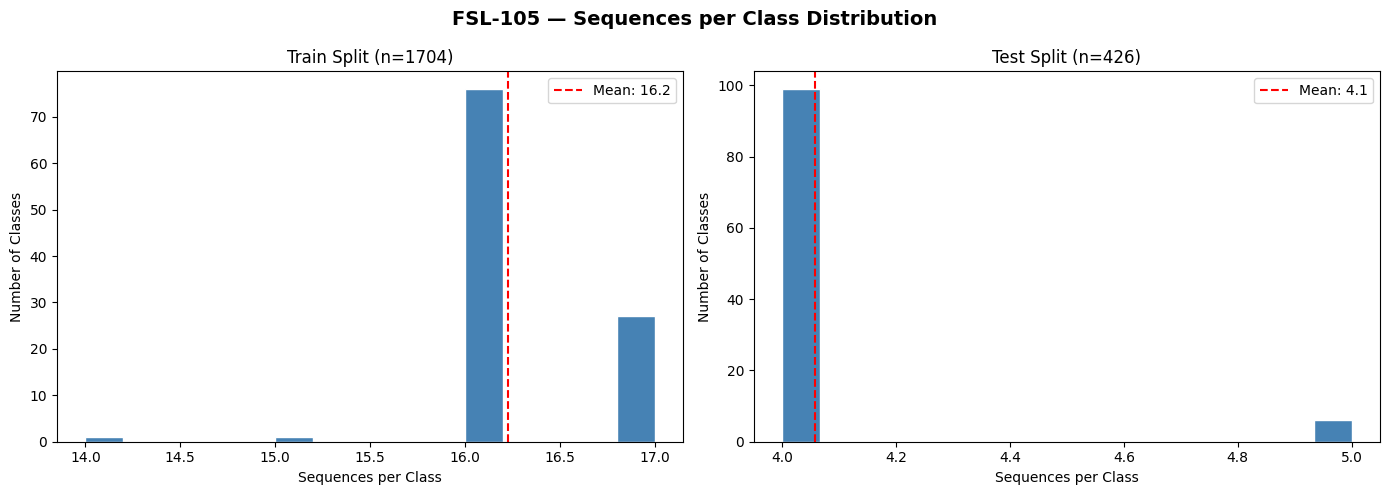

In [3]:
# Sequences per class distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('FSL-105 — Sequences per Class Distribution', fontsize=14, fontweight='bold')

for ax, manifest, split in zip(axes,
    [train_manifest, test_manifest],
    ['Train', 'Test']):
    counts = manifest['label_name'].value_counts() if 'label_name' in manifest.columns \
             else manifest['label_id'].value_counts()
    ax.hist(counts.values, bins=15, color='steelblue', edgecolor='white')
    ax.set_title(f'{split} Split (n={len(manifest)})')
    ax.set_xlabel('Sequences per Class')
    ax.set_ylabel('Number of Classes')
    ax.axvline(counts.mean(), color='red', linestyle='--',
               label=f'Mean: {counts.mean():.1f}')
    ax.legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fsl_class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()


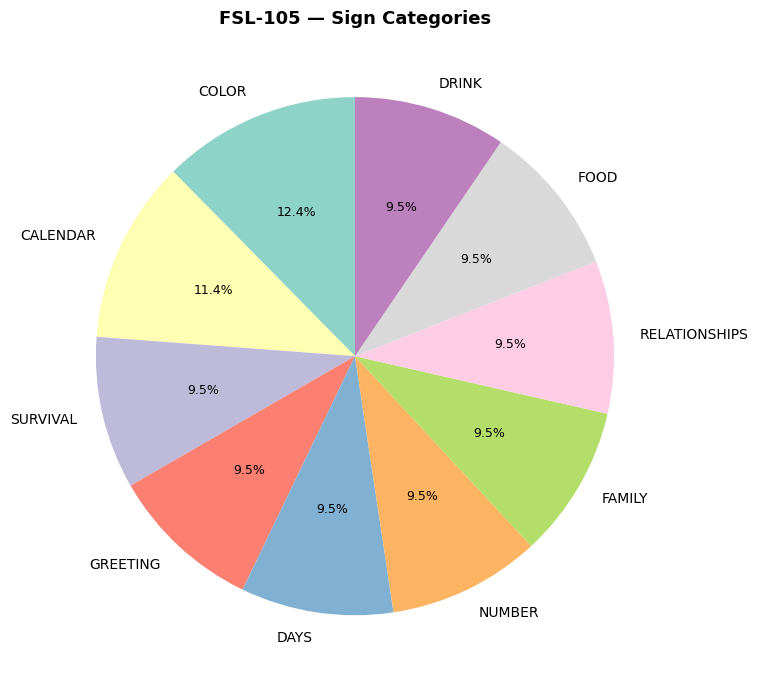

In [4]:
# Category breakdown pie chart
if 'category' in label_map_df.columns:
    cat_counts = label_map_df['category'].value_counts()
    fig, ax = plt.subplots(figsize=(9, 7))
    wedges, texts, autotexts = ax.pie(
        cat_counts.values,
        labels=cat_counts.index,
        autopct='%1.1f%%',
        startangle=90,
        colors=plt.cm.Set3.colors[:len(cat_counts)],
    )
    for text in autotexts:
        text.set_fontsize(9)
    ax.set_title('FSL-105 — Sign Categories', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'fsl_categories.png', dpi=150, bbox_inches='tight')
    plt.show()


## 2. Training Curves

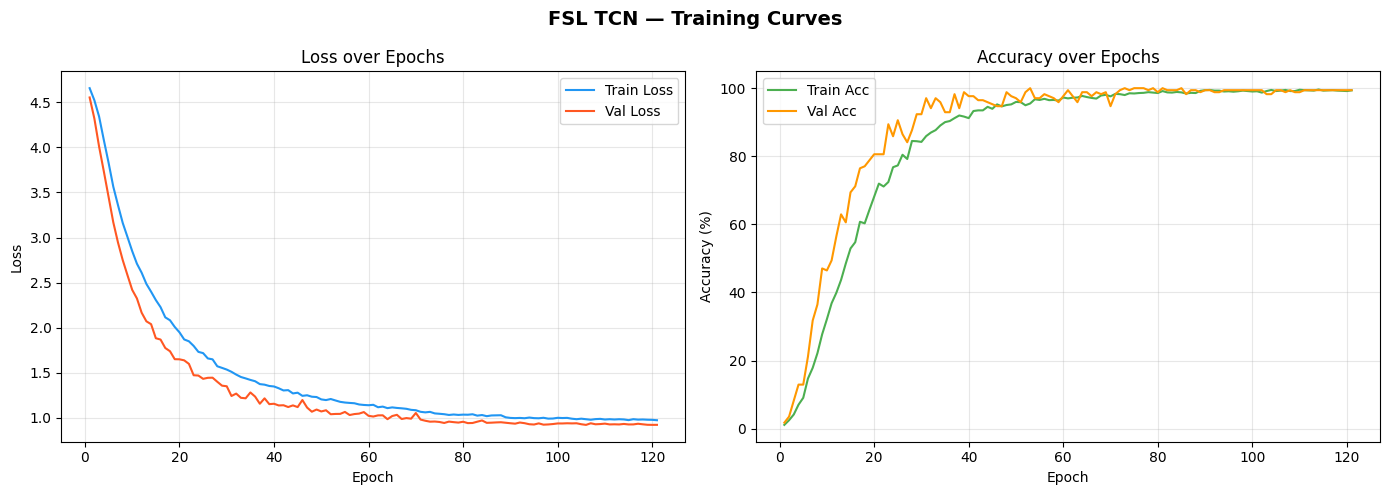

Total epochs trained: 121
Best val loss       : 0.9214 (epoch 106)
Best val acc        : 100.00% (epoch 53)


In [5]:
# Load training log
if TRAINING_LOG.exists():
    log_df = pd.read_csv(TRAINING_LOG)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle('FSL TCN — Training Curves', fontsize=14, fontweight='bold')

    # Loss
    axes[0].plot(log_df['epoch'], log_df['train_loss'], label='Train Loss', color='#2196F3')
    axes[0].plot(log_df['epoch'], log_df['val_loss'],   label='Val Loss',   color='#FF5722')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].set_title('Loss over Epochs')
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # Accuracy
    axes[1].plot(log_df['epoch'], log_df['train_acc'], label='Train Acc', color='#4CAF50')
    axes[1].plot(log_df['epoch'], log_df['val_acc'],   label='Val Acc',   color='#FF9800')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy (%)')
    axes[1].set_title('Accuracy over Epochs')
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'fsl_training_curves.png', dpi=150, bbox_inches='tight')
    plt.show()

    print(f'Total epochs trained: {len(log_df)}')
    print(f'Best val loss       : {log_df["val_loss"].min():.4f} (epoch {log_df["val_loss"].idxmin()+1})')
    print(f'Best val acc        : {log_df["val_acc"].max():.2f}% (epoch {log_df["val_acc"].idxmax()+1})')
else:
    print('[info] Training log not found — skipping training curves.')


## 3. Model Architecture

In [6]:
checkpoint = torch.load(MODEL_PATH, map_location=device)

model = SignTCN(
    feature_dim=checkpoint['feature_dim'],
    num_classes=checkpoint['num_classes'],
    channels=checkpoint['channels'],
    dilations=checkpoint['dilations'],
    kernel_size=checkpoint['kernel_size'],
    dropout=checkpoint['dropout'],
    fc_dropout=checkpoint['fc_dropout'],
).to(device)
model.load_state_dict(checkpoint['model_state'])
model.eval()

print('=' * 55)
print('MODEL ARCHITECTURE')
print('=' * 55)
print(f'  Architecture     : Temporal Convolutional Network (TCN)')
print(f'  Input shape      : (batch, 64, 302)')
print(f'  TCN blocks       : {len(checkpoint["channels"])}')
print(f'  Channels         : {checkpoint["channels"]}')
print(f'  Dilations        : {checkpoint["dilations"]}')
print(f'  Kernel size      : {checkpoint["kernel_size"]}')
print(f'  Dropout          : {checkpoint["dropout"]}')
print(f'  FC Dropout       : {checkpoint["fc_dropout"]}')
print(f'  Output classes   : {checkpoint["num_classes"]}')
print(f'  Trainable params : {sum(p.numel() for p in model.parameters() if p.requires_grad):,}')
print(f'  Best epoch       : {checkpoint["epoch"]}')
print(f'  Internal val acc : {checkpoint["val_acc"]*100:.2f}%')


MODEL ARCHITECTURE
  Architecture     : Temporal Convolutional Network (TCN)
  Input shape      : (batch, 64, 302)
  TCN blocks       : 4
  Channels         : [64, 128, 128, 256]
  Dilations        : [1, 2, 4, 8]
  Kernel size      : 3
  Dropout          : 0.2
  FC Dropout       : 0.4
  Output classes   : 105
  Trainable params : 602,281
  Best epoch       : 106
  Internal val acc : 99.41%


## 4. Test Set Evaluation

In [7]:
class TestDataset(Dataset):
    def __init__(self, features_dir, manifest_csv):
        self.samples = []
        with open(manifest_csv, encoding='utf-8-sig') as f:
            for row in csv.DictReader(f):
                npy_path = features_dir / row['npy_file']
                if npy_path.exists():
                    self.samples.append((npy_path, int(row['label_id'])))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        npy_path, label_id = self.samples[idx]
        seq = np.load(str(npy_path)).astype(np.float32)
        return torch.from_numpy(seq), torch.tensor(label_id, dtype=torch.long)

# Load label map
label_map = {}
with open(LABEL_MAP, encoding='utf-8-sig') as f:
    for row in csv.DictReader(f):
        label_map[int(row['label_id'])] = row['gloss']
class_names = [label_map[i] for i in range(len(label_map))]

# Run inference
test_dataset = TestDataset(TEST_DIR, TEST_MANIFEST)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)
print(f'Test sequences: {len(test_dataset)}')

all_preds, all_labels = [], []
with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        logits = model(x)
        preds  = logits.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(y.numpy())

all_preds  = np.array(all_preds)
all_labels = np.array(all_labels)

_acc  = accuracy_score(all_labels, all_preds)
_prec = precision_score(all_labels, all_preds, average='macro', zero_division=0)
_rec  = recall_score(all_labels, all_preds, average='macro', zero_division=0)
_f1   = f1_score(all_labels, all_preds, average='macro', zero_division=0)

print('=' * 55)
print('OVERALL TEST RESULTS')
print('=' * 55)
print(f'  Test samples : {len(all_labels)}')
print(f'  Accuracy     : {_acc*100:.2f}%')
print(f'  Precision    : {_prec*100:.2f}%  (macro)')
print(f'  Recall       : {_rec*100:.2f}%  (macro)')
print(f'  F1 Score     : {_f1*100:.2f}%  (macro)')


Test sequences: 426
OVERALL TEST RESULTS
  Test samples : 426
  Accuracy     : 98.59%
  Precision    : 98.98%  (macro)
  Recall       : 98.57%  (macro)
  F1 Score     : 98.56%  (macro)


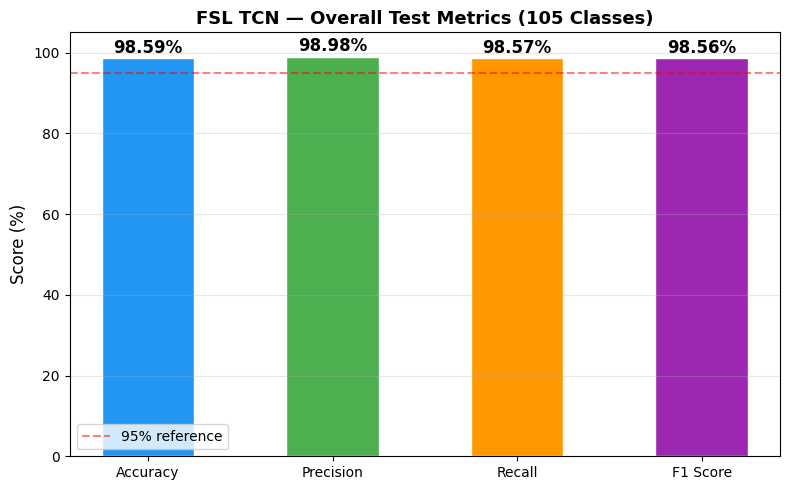

In [8]:
# Metrics bar chart
metrics = {
    'Accuracy':  _acc * 100,
    'Precision': _prec * 100,
    'Recall':    _rec * 100,
    'F1 Score':  _f1 * 100,
}

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(metrics.keys(), metrics.values(),
              color=['#2196F3', '#4CAF50', '#FF9800', '#9C27B0'],
              edgecolor='white', width=0.5)

for bar, val in zip(bars, metrics.values()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f'{val:.2f}%', ha='center', va='bottom', fontweight='bold', fontsize=12)

ax.set_ylim(0, 105)
ax.set_ylabel('Score (%)', fontsize=12)
ax.set_title('FSL TCN — Overall Test Metrics (105 Classes)', fontsize=13, fontweight='bold')
ax.axhline(y=95, color='red', linestyle='--', alpha=0.5, label='95% reference')
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fsl_overall_metrics.png', dpi=150, bbox_inches='tight')
plt.show()


## 5. Per-Class Accuracy

In [9]:
# Per-class accuracy
per_class = defaultdict(lambda: {'correct': 0, 'total': 0})
for pred, label in zip(all_preds, all_labels):
    per_class[label]['total']   += 1
    if pred == label:
        per_class[label]['correct'] += 1

class_acc = []
for class_id in range(len(label_map)):
    total   = per_class[class_id]['total']
    correct = per_class[class_id]['correct']
    acc_c   = correct / total if total > 0 else 0.0
    class_acc.append((class_names[class_id], acc_c * 100, correct, total))

class_acc_df = pd.DataFrame(class_acc, columns=['gloss', 'accuracy', 'correct', 'total'])
class_acc_df = class_acc_df.sort_values('accuracy', ascending=False)

print(f'Classes at 100%  : {(class_acc_df["accuracy"] == 100).sum()}')
print(f'Classes above 80%: {(class_acc_df["accuracy"] >= 80).sum()}')
print(f'Classes below 50%: {(class_acc_df["accuracy"] < 50).sum()}')
print(f'Avg class accuracy: {class_acc_df["accuracy"].mean():.2f}%')


Classes at 100%  : 100
Classes above 80%: 100
Classes below 50%: 0
Avg class accuracy: 98.57%


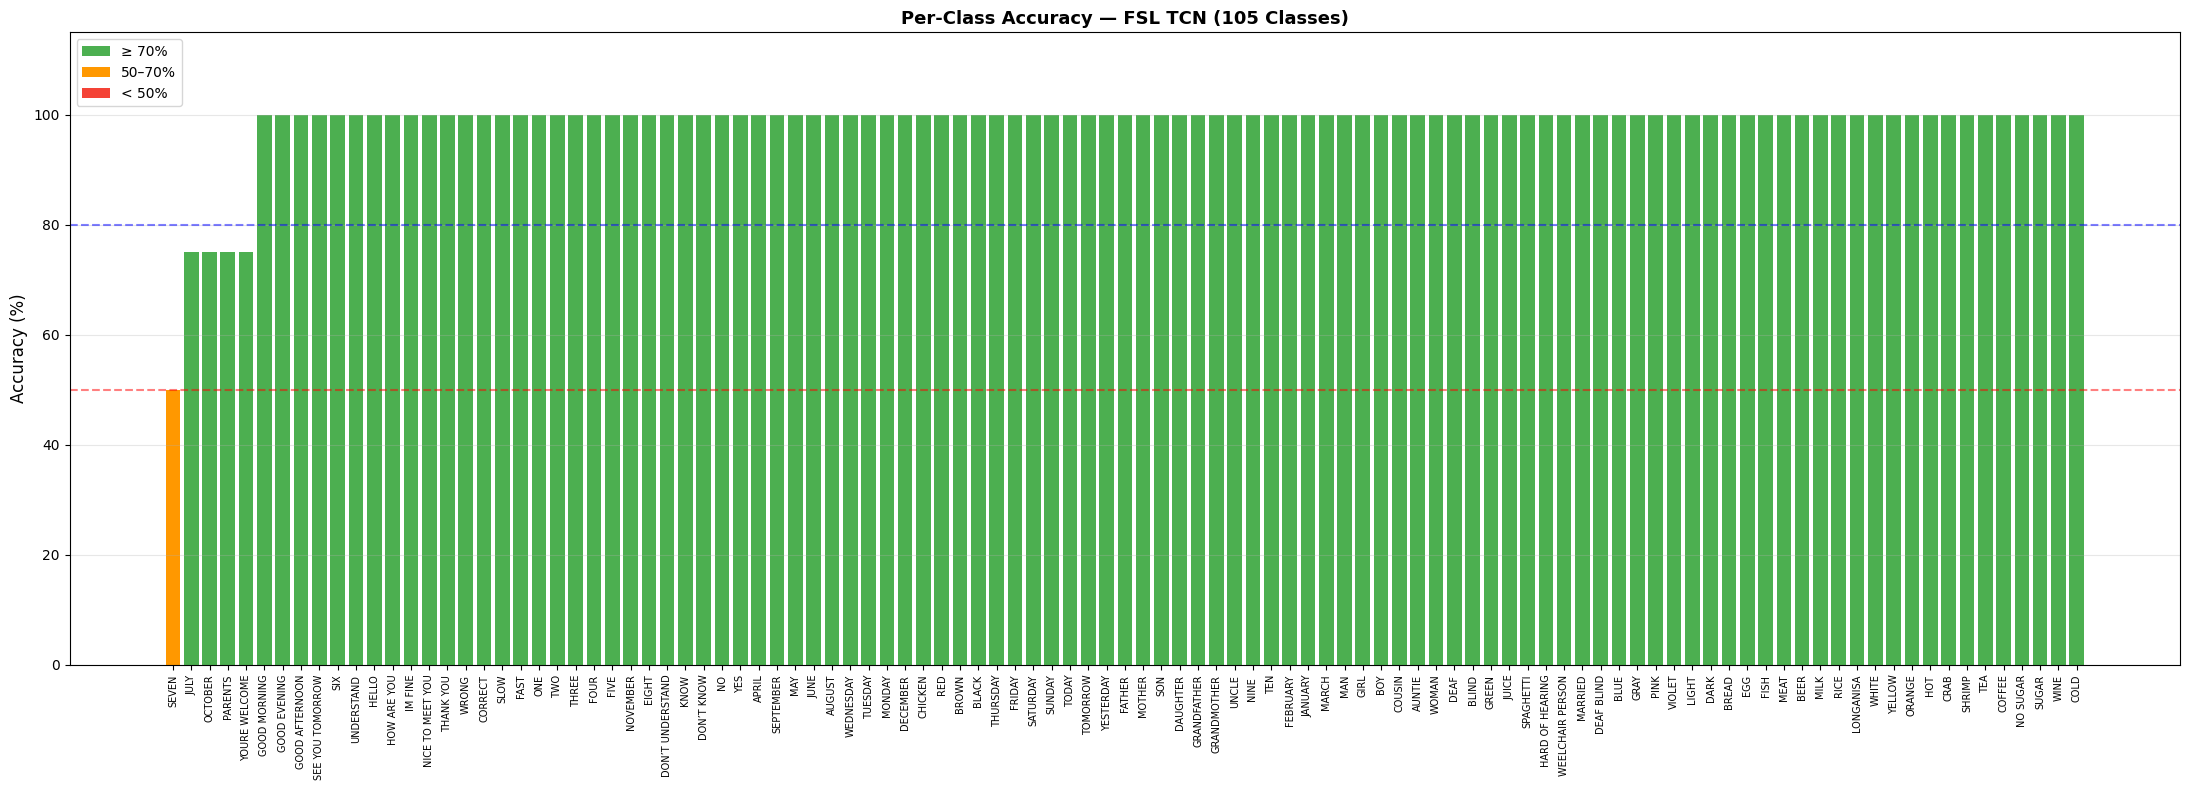

In [10]:
# Per-class accuracy bar chart
df_sorted = class_acc_df.sort_values('accuracy')
colors = ['#f44336' if a < 50 else '#FF9800' if a < 70 else '#4CAF50'
          for a in df_sorted['accuracy']]

fig, ax = plt.subplots(figsize=(22, 8))
ax.bar(range(len(df_sorted)), df_sorted['accuracy'],
       color=colors, edgecolor='none', width=0.8)

ax.set_xticks(range(len(df_sorted)))
ax.set_xticklabels(df_sorted['gloss'], rotation=90, fontsize=7)
ax.set_ylabel('Accuracy (%)', fontsize=12)
ax.set_title('Per-Class Accuracy — FSL TCN (105 Classes)', fontsize=13, fontweight='bold')
ax.axhline(y=80, color='blue', linestyle='--', alpha=0.5, label='80%')
ax.axhline(y=50, color='red',  linestyle='--', alpha=0.5, label='50%')
ax.set_ylim(0, 115)
ax.grid(axis='y', alpha=0.3)

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#4CAF50', label='≥ 70%'),
    Patch(facecolor='#FF9800', label='50–70%'),
    Patch(facecolor='#f44336', label='< 50%'),
]
ax.legend(handles=legend_elements, loc='upper left', fontsize=10)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fsl_per_class_accuracy.png', dpi=150, bbox_inches='tight')
plt.show()


## 6. Confusion Matrix

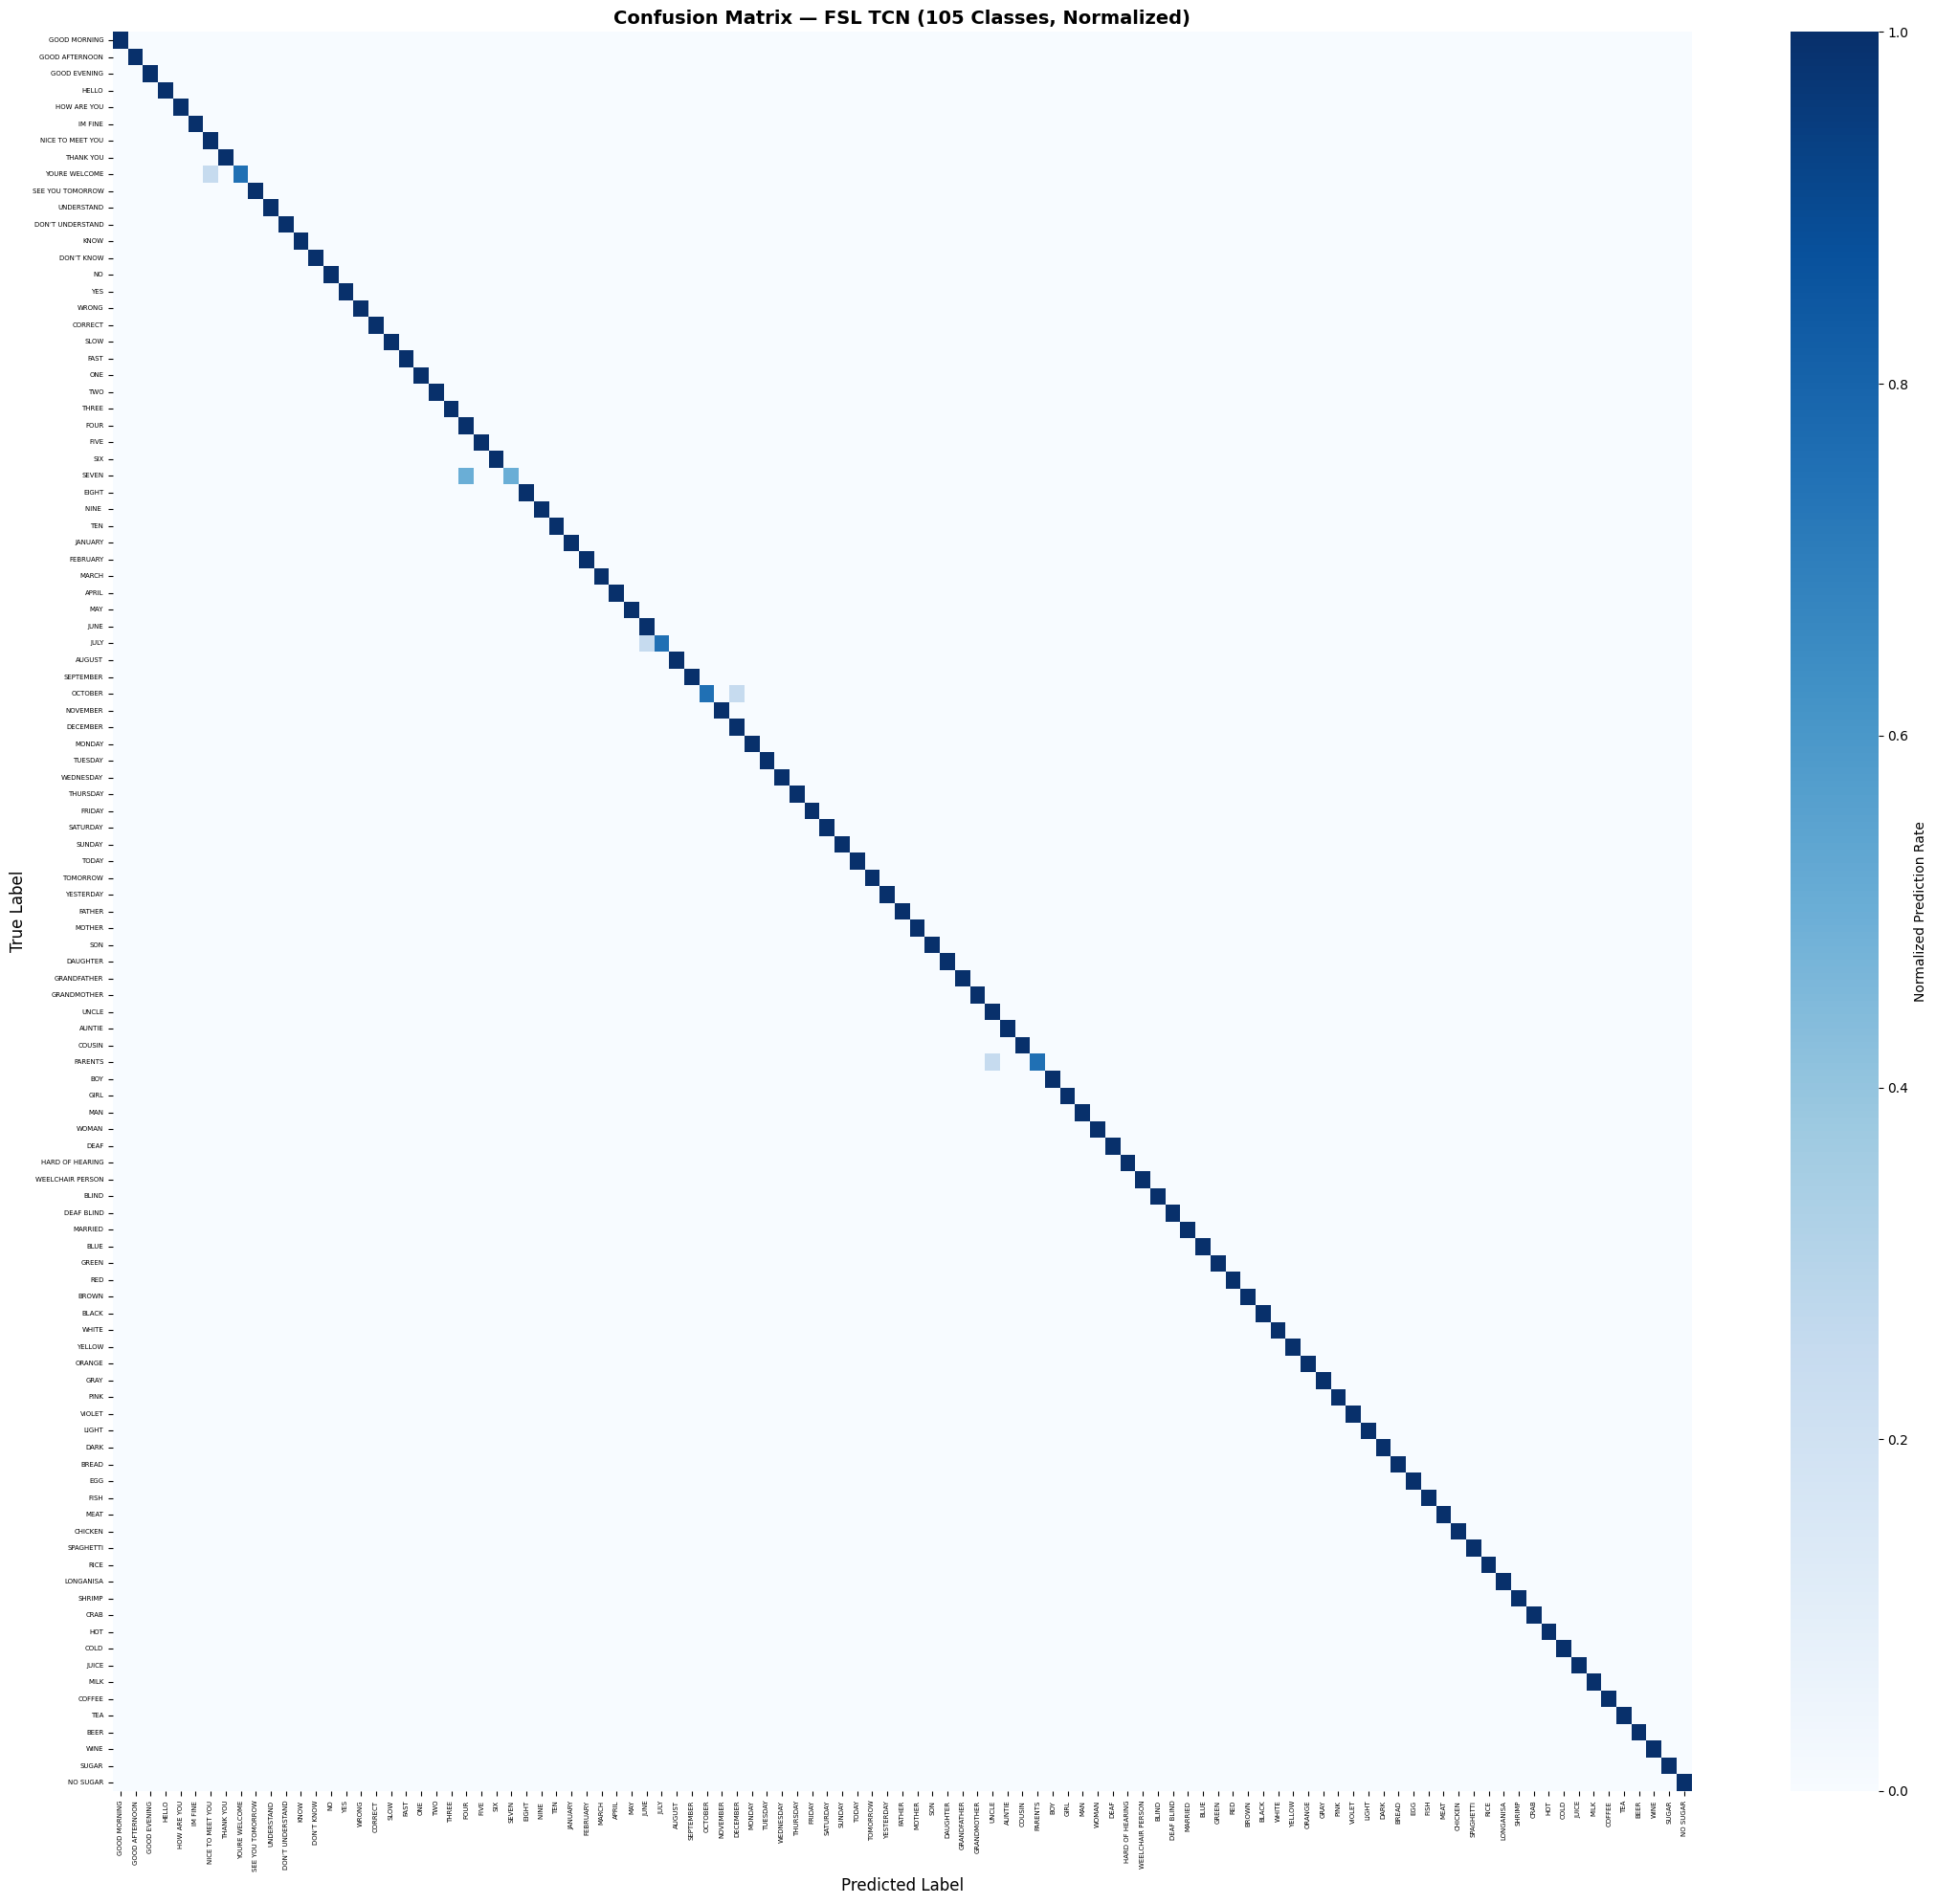

In [11]:
# Full confusion matrix
cm = confusion_matrix(all_labels, all_preds, labels=list(range(len(label_map))))
cm_norm = cm.astype(float)
row_sums = cm.sum(axis=1, keepdims=True)
row_sums[row_sums == 0] = 1
cm_norm = cm_norm / row_sums

fig, ax = plt.subplots(figsize=(22, 20))
sns.heatmap(
    cm_norm,
    xticklabels=class_names,
    yticklabels=class_names,
    cmap='Blues',
    vmin=0, vmax=1,
    ax=ax,
    cbar_kws={'label': 'Normalized Prediction Rate'},
    linewidths=0,
)
ax.set_xlabel('Predicted Label', fontsize=12)
ax.set_ylabel('True Label', fontsize=12)
ax.set_title('Confusion Matrix — FSL TCN (105 Classes, Normalized)', fontsize=14, fontweight='bold')
ax.tick_params(axis='x', labelsize=5, rotation=90)
ax.tick_params(axis='y', labelsize=5, rotation=0)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fsl_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()


CONFUSED SIGN PAIRS
         True        Predicted  Count Error Rate
        SEVEN             FOUR      2      50.0%
YOURE WELCOME NICE TO MEET YOU      1      25.0%
         JULY             JUNE      1      25.0%
      OCTOBER         DECEMBER      1      25.0%
      PARENTS            UNCLE      1      25.0%


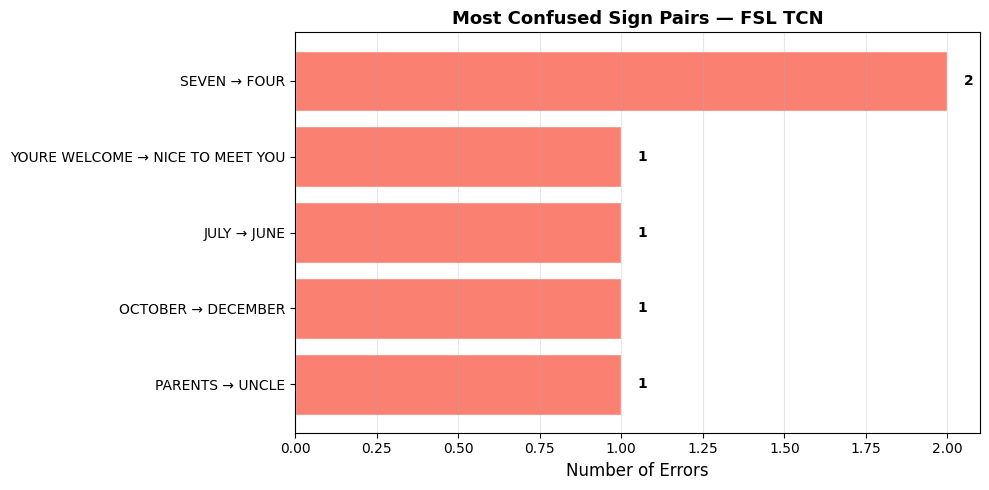

In [12]:
# Confused pairs
confused_pairs = []
for i in range(len(label_map)):
    for j in range(len(label_map)):
        if i != j and cm[i][j] > 0:
            confused_pairs.append({
                'True':       class_names[i],
                'Predicted':  class_names[j],
                'Count':      int(cm[i][j]),
                'Error Rate': f"{cm[i][j]/cm[i].sum()*100:.1f}%"
            })
confused_pairs.sort(key=lambda x: x['Count'], reverse=True)

if confused_pairs:
    print('CONFUSED SIGN PAIRS')
    confused_df = pd.DataFrame(confused_pairs)
    print(confused_df.to_string(index=False))

    # Chart
    top = confused_pairs[:10]
    labels_pairs = [f"{p['True']} → {p['Predicted']}" for p in top]
    counts = [p['Count'] for p in top]

    fig, ax = plt.subplots(figsize=(10, 5))
    bars = ax.barh(labels_pairs[::-1], counts[::-1], color='salmon', edgecolor='white')
    for bar, count in zip(bars, counts[::-1]):
        ax.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height()/2,
                str(count), va='center', fontsize=10, fontweight='bold')
    ax.set_xlabel('Number of Errors', fontsize=12)
    ax.set_title('Most Confused Sign Pairs — FSL TCN', fontsize=13, fontweight='bold')
    ax.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'fsl_confused_pairs.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('No confused pairs — perfect classification!')


## 7. Best and Worst Performing Classes

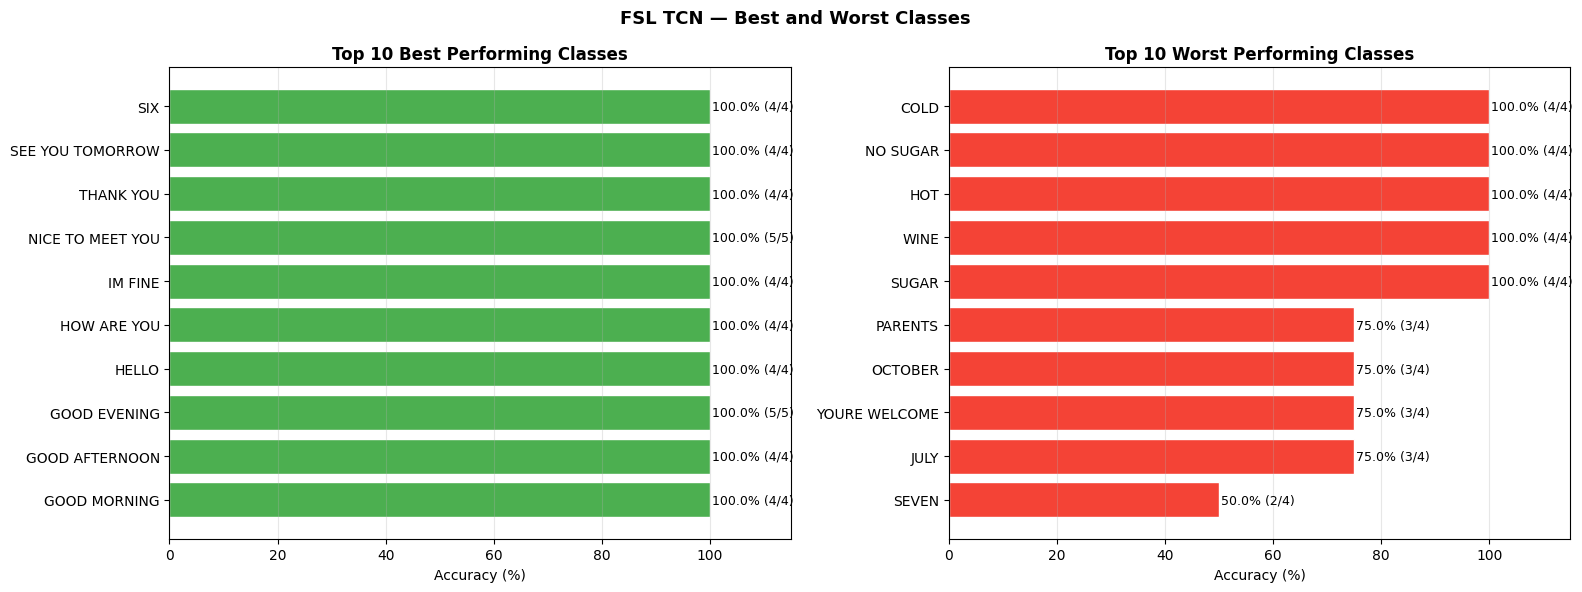

In [13]:
best  = class_acc_df.head(10)
worst = class_acc_df.tail(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].barh(best['gloss'], best['accuracy'], color='#4CAF50', edgecolor='white')
for i, (acc, correct, total) in enumerate(zip(best['accuracy'], best['correct'], best['total'])):
    axes[0].text(acc + 0.3, i, f'{acc:.1f}% ({correct}/{total})',
                 va='center', fontsize=9)
axes[0].set_xlim(0, 115)
axes[0].set_xlabel('Accuracy (%)')
axes[0].set_title('Top 10 Best Performing Classes', fontweight='bold')
axes[0].grid(axis='x', alpha=0.3)

worst_sorted = worst.sort_values('accuracy')
axes[1].barh(worst_sorted['gloss'], worst_sorted['accuracy'],
             color='#f44336', edgecolor='white')
for i, (acc, correct, total) in enumerate(zip(
        worst_sorted['accuracy'], worst_sorted['correct'], worst_sorted['total'])):
    axes[1].text(acc + 0.3, i, f'{acc:.1f}% ({correct}/{total})',
                 va='center', fontsize=9)
axes[1].set_xlim(0, 115)
axes[1].set_xlabel('Accuracy (%)')
axes[1].set_title('Top 10 Worst Performing Classes', fontweight='bold')
axes[1].grid(axis='x', alpha=0.3)

plt.suptitle('FSL TCN — Best and Worst Classes', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fsl_best_worst_classes.png', dpi=150, bbox_inches='tight')
plt.show()


## 8. Summary Table

In [14]:
summary = {
    'Metric': [
        'Dataset', 'Number of Classes', 'Train Sequences', 'Test Sequences',
        'Feature Dimension', 'Sequence Length',
        'Model', 'Parameters', 'Best Epoch',
        'Test Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1',
        'Best Class Accuracy', 'Worst Class Accuracy',
        'Classes at 100%', 'Classes below 50%'
    ],
    'Value': [
        'FSL-105', '105',
        str(len(train_manifest)), str(len(test_manifest)),
        '302', '64 frames',
        'TCN (4 blocks: 64→128→128→256)', '602,281',
        str(checkpoint['epoch']),
        f"{_acc*100:.2f}%",
        f"{_prec*100:.2f}%",
        f"{_rec*100:.2f}%",
        f"{_f1*100:.2f}%",
        f"{class_acc_df['accuracy'].max():.1f}%",
        f"{class_acc_df['accuracy'].min():.1f}%",
        str((class_acc_df['accuracy'] == 100).sum()),
        str((class_acc_df['accuracy'] < 50).sum()),
    ]
}

summary_df = pd.DataFrame(summary)
print('FSL TCN — FINAL RESULTS SUMMARY')
print('=' * 50)
for _, row in summary_df.iterrows():
    print(f"  {row['Metric']:<25} {row['Value']}")


FSL TCN — FINAL RESULTS SUMMARY
  Dataset                   FSL-105
  Number of Classes         105
  Train Sequences           1704
  Test Sequences            426
  Feature Dimension         302
  Sequence Length           64 frames
  Model                     TCN (4 blocks: 64→128→128→256)
  Parameters                602,281
  Best Epoch                106
  Test Accuracy             98.59%
  Macro Precision           98.98%
  Macro Recall              98.57%
  Macro F1                  98.56%
  Best Class Accuracy       100.0%
  Worst Class Accuracy      50.0%
  Classes at 100%           100
  Classes below 50%         0


## 9. Classification Report

In [15]:
report = classification_report(
    all_labels, all_preds,
    target_names=class_names,
    zero_division=0
)
print(report)

with open(OUTPUT_DIR / 'fsl_classification_report.txt', 'w') as f:
    f.write('FSL TCN Classification Report\n')
    f.write('=' * 60 + '\n')
    f.write(report)
print('Classification report saved.')


                  precision    recall  f1-score   support

    GOOD MORNING       1.00      1.00      1.00         4
  GOOD AFTERNOON       1.00      1.00      1.00         4
    GOOD EVENING       1.00      1.00      1.00         5
           HELLO       1.00      1.00      1.00         4
     HOW ARE YOU       1.00      1.00      1.00         4
         IM FINE       1.00      1.00      1.00         4
NICE TO MEET YOU       0.83      1.00      0.91         5
       THANK YOU       1.00      1.00      1.00         4
   YOURE WELCOME       1.00      0.75      0.86         4
SEE YOU TOMORROW       1.00      1.00      1.00         4
      UNDERSTAND       1.00      1.00      1.00         4
DON’T UNDERSTAND       1.00      1.00      1.00         4
            KNOW       1.00      1.00      1.00         4
      DON’T KNOW       1.00      1.00      1.00         4
              NO       1.00      1.00      1.00         4
             YES       1.00      1.00      1.00         4
           WR